## Fréchet pitfalls. Flip, Clip, Parametrise.

When calculating the discrete Frechet metric, we try to find the smallest length (length of the longest segment) of any coupling between two nodes of a polyline. Ideally, all our centrelines would begin at the same start point and finish at the same end point. But it is not the case for the hydraulic lines. The discrete frechet metric would be dominated by this discrepancy. 

Another thing to bear in mind is the order of parametrisation of our polylines.

In [4]:
cd ..

c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines


In [5]:
import yaml
import numpy as np
from base.frechet_dist import frdist
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

In [6]:
plt.rcParams["font.family"] = "Arial"

In [62]:
# a convenience function to resample a centreline using a 1d interpolator. 
def parametrise_ct(ct, eps):
    t = np.zeros(ct.shape[0])

    segments = np.linalg.norm(np.diff(ct, axis = 0), axis = 1)
    
    cumsum = np.cumsum(segments)

    L = np.max(cumsum)
    t[1:] =  cumsum / L

    x_interp  = interp1d(t, ct[:,  0])
    y_interp  = interp1d(t, ct[:,  1])
    if ct.shape[1] == 3:
        z_interp  = interp1d(t, ct[:,  2])

    # now we work out the reparametrisation so that the average segment length is close to the required delta.
    ti = []
    t0 = 0
    for segment in segments:
        r = np.ceil(segment/eps)
        increments =  [t0+ i * segment / r for i in np.arange(0, r)]
        for increment in increments:
            ti.append(increment / L)
        t0 +=segment
    
    ti.append(1)
        
    if ct.shape[1] == 3:
        return np.vstack([x_interp(ti), y_interp(ti), z_interp(ti)]).T
    else:
        return np.vstack([x_interp(ti), y_interp(ti)]).T


We choose first an epsilon: this is the average segment length we wish to retain at the end of the reparametrisation of the polygonal curve. To make sure that the discrete fréchet metric calculated is close to the actual fréchet distance, we precompute the metric on the unrefined polygonal lines, then choose epsilon so that $\epsilon << \delta_{DF}$.  For each segment in the sequence, we calculate its length $l$, and work out in how many subsegments $r$ it should be divided.

$r = \lceil l / \epsilon \rceil$

We then refine the centreline by adding equally spaced nodes on each linear segment.

In [63]:
with open(f"./notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct_1_kwargs = p["ct1_kwargs"]
ct_2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

In [64]:
P = np.array([[1, 0],
              [2, 0],
              [3, 0],
              [4, 0],
              [5, 0]])
Q = np.array([[1, 1],
              [2, 1],
              [3, 1],
              [4, 1],
              [5, 1]])

couple_1 = [[0,0],[0,1],[0,2], [0,3],[1,3],[2,3],[3,3],[4,4]]
couple_2 = [[0,4],[1,3],[1,2],[2,2],[2,1],[3,0], [4,0]]
couple_3 = [[0,0],[1,1], [2,2], [3,3], [4,4]]

In [65]:
import matplotlib.patheffects as pe

In [66]:
couple_1_str = ""
for s,e in couple_1:
    couple_1_str += f"$(u_{{{s}}},v_{{{e}}})$,"

couple_2_str = ""
for s,e in couple_2:
    couple_2_str += f"$(u_{{{s}}},v_{{{4-e}}})$,"

couple_3_str = ""
for s,e in couple_3:
    couple_3_str += f"$(u_{{{s}}},v_{{{e}}})$,"


## What is a coupling ??

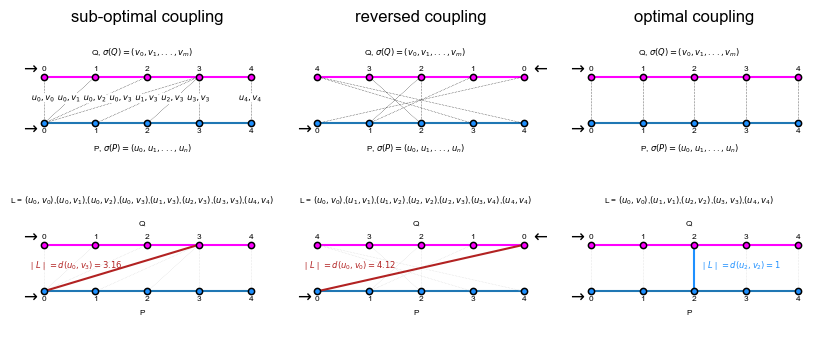

In [67]:
fig, axes = plt.subplots(2, 3, figsize = (10, 4))

ax = axes[0, 0]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")

for link in couple_1:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T,  ls = "dotted", color = "k", lw=.4)
    centre = (P[s] + Q[e]) / 2

    ax.text(*centre, f"$u_{{{s}}},v_{{{e}}}$", color="k", 
            fontsize=6, 
            ha="center", 
            path_effects=[pe.withStroke(linewidth=4, foreground="white")])

ax.text(0.9, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

ax = axes[1, 0]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")
s, e = couple_1[3]
ax.plot(*np.vstack([P[s], Q[e]]).T, color="firebrick", ls = "-", zorder = 10)

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")

for link in couple_1:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T,  ls = "dotted", color = "lightgrey", lw=.4)

d = np.linalg.norm(P[0] - Q[3])

## annotate the infemum link length. 
ax.text(0.7, 0.5, f"$\\mid L\\mid =d (u_{{0}}, v_{{3}})  = {d:.2f}$", color="firebrick", fontsize=6, ha="left")
ax.text(0.9, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

ax = axes[0, 1]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")

for link in couple_2:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T, ls = "dotted", color = "k", lw=.4)

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q[::-1]):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")
ax.text(5.1, 1.1, f"$\\leftarrow$", fontsize=12, ha="left")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")


ax = axes[1, 1]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")

s, e = couple_2[0]
ax.plot(*np.vstack([P[s], Q[e]]).T, color="firebrick", ls = "-", zorder = 10)

for link in couple_2:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T, ls = "dotted", color = "lightgrey", lw=.4)

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q[::-1]):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")

d = np.linalg.norm(P[0] - Q[-1])
## annotate the infemum link length. 
ax.text(0.7, 0.5, f"$\\mid L\\mid =d (u_{{0}}, v_{{0}}) = {d:.2f}$", color="firebrick", fontsize=6, ha="left")
ax.text(5.1, 1.1, f"$\\leftarrow$", fontsize=12, ha="left")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")


ax = axes[0, 2]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")

for link in couple_3:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T,ls = "dotted", color = "k", lw=.4)

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")


for ax, label, coupling_str in zip(axes[0], ("sub-optimal", "reversed", "optimal"), (couple_1_str, couple_2_str, couple_3_str)):
    ax.set_title(f"{label} coupling")

    ax.text(2.9,1.4,"Q, $\\sigma (Q) = (v_{0}, v_{1}, ..., v_{m})$", va="bottom", ha="center", fontsize=6)
    ax.text(2.9,-0.4,"P, $\\sigma (P) = (u_{0}, u_{1}, ..., u_{n})$", va="top", ha="center", fontsize= 6)
    ax.text(2.9, -1.5, f"L = {coupling_str[:-1]}", va="top", ha="center", fontsize=6)
    ax.set_ylim(-1, 2)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ["bottom", "top", "left", "right"]:
        ax.spines[spine].set_visible(False)

ax.text(0.9, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

ax = axes[1, 2]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")

s, e = couple_3[2]
ax.plot(*np.vstack([P[s], Q[e]]).T, color="dodgerblue", ls = "-", zorder = 10)
for link in couple_3:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T,ls = "dotted", color = "lightgrey", lw=.4)

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")

## annotate the infemum link length. 
ax.text(3.1, 0.5, "$\\mid L \\mid =d (u_{{2}}, v_{{2}})  = 1$", color="dodgerblue", fontsize=6, ha="left")
ax.text(0.9, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

for ax, label in zip(axes[1], ("sub-optimal", "reversed", "optimal")):
    ax.text(2.9,1.4,"Q", va="bottom", ha="center", fontsize=6)
    ax.text(2.9,-0.4,"P", va="top", ha="center", fontsize=6)

    ax.set_ylim(-1, 2)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ["bottom", "top", "left", "right"]:
        ax.spines[spine].set_visible(False)
    ax.set_facecolor("None")
    
plt.savefig("./temp/figures/couplings.png", dpi = 300)
plt.savefig("./temp/figures/couplings.pdf")
plt.show()

In [68]:
frdist(P, Q)

np.float64(1.0)

Now we show an example of trimming the longer of the two paths. 

In [69]:
P = np.array([[1.75, 0.25],
              [3, 0.25],
              [4.25, 0.25]])
Q = np.array([[1, 1],
              [2, 1],
              [3, 1],
              [4, 1],
              [5, 1]])


couple_1 =  [[0,0],[0,1], [1,2], [2,3], [2, 4]]
couple_2 = [[0,0],[1,1], [2,2]]

0.7905694150420949
35 33
[[ 0.  0.]
 [ 1.  1.]
 [ 2.  2.]
 [ 3.  3.]
 [ 4.  4.]
 [ 5.  5.]
 [ 6.  6.]
 [ 6.  7.]
 [ 7.  8.]
 [ 8.  9.]
 [ 9. 10.]
 [10. 11.]
 [11. 12.]
 [12. 13.]
 [13. 14.]
 [14. 15.]
 [15. 16.]
 [16. 17.]
 [17. 18.]
 [18. 19.]
 [19. 20.]
 [20. 21.]
 [21. 22.]
 [22. 23.]
 [23. 24.]
 [24. 25.]
 [25. 26.]
 [26. 27.]
 [26. 28.]
 [27. 29.]
 [28. 30.]
 [29. 31.]
 [30. 32.]
 [31. 33.]
 [32. 34.]]


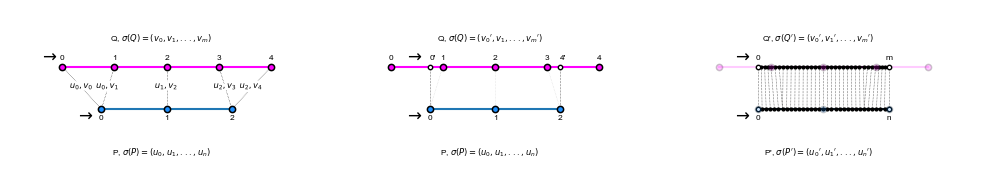

In [73]:
fig, axes = plt.subplots(1, 3, figsize = (10, 2))

ax = axes[0]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")


# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")

for link in couple_1:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T,  ls = "dotted", color = "k", lw=.4)
    centre = (P[s] + Q[e]) / 2

    ax.text(*centre, f"$u_{{{s}}},v_{{{e}}}$", color="k", 
            fontsize=6, 
            ha="center", 
            path_effects=[pe.withStroke(linewidth=4, foreground="white")])
ax.text(2.9,1.4,"Q, $\\sigma (Q) = (v_{0}, v_{1}, ..., v_{m})$", va="bottom", ha="center", fontsize=6)
ax.text(2.9,-0.4,"P, $\\sigma (P) = (u_{0}, u_{1}, ..., u_{n})$", va="top", ha="center", fontsize= 6)

ax.text(0.9, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(1.6, 0.15, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

ax = axes[1]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")


# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")



# projection of a point on a segment.
n = (Q[1] - Q[0]) / np.linalg.norm(Q[1] - Q[0])
q = (P[0] - Q[0])
qprime = np.dot(n, q)*n
sprime = Q[0]+qprime

n = (Q[-2] - Q[-1]) / np.linalg.norm(Q[-2] - Q[-1])
q = (P[-1] - Q[-1])
qprime = np.dot(n, q)*n
eprime = Q[-1]+qprime

for k, link in enumerate(couple_1):
    s, e = link
    if k == 0:
        ax.plot(*np.vstack([P[0], sprime]).T, ls= "dotted", color = "k", lw=.4)
    elif k == len(couple_1) -1:
        ax.plot(*np.vstack([P[-1], eprime]).T, ls= "dotted", color = "k", lw=.4)
    else:
        ax.plot(*np.vstack([P[s], Q[e]]).T,  ls = "dotted", color = "lightgrey",lw=.4)
    centre = (P[s] + Q[e]) / 2


ax.scatter(*sprime, zorder =20, color = "white", s= 10, edgecolors="k")
ax.scatter(*eprime, zorder =20, color = "white", s= 10, edgecolors="k")
ax.text(sprime[0],sprime[1]+0.1, "0'", fontsize = 6, va="bottom")
ax.text(eprime[0],eprime[1]+0.1,"4'", fontsize = 6, va="bottom")
ax.text(2.9,1.4,"Q, $\\sigma (Q) = ({v_{0}}', v_{1}, ..., {v_{m}}')$", va="bottom", ha="center", fontsize=6)
ax.text(2.9,-0.4,"P, $\\sigma (P) = (u_{0}, u_{1}, ..., u_{n})$", va="top", ha="center", fontsize= 6)
ax.text(1.6, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(1.6, 0.15, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")



ax = axes[2]

Qprime = np.vstack([sprime, Q[1:-1], eprime])
print(frdist(P, Qprime))

Pnew = parametrise_ct(P, eps=0.1*frdist(P, Qprime))


Qnew = parametrise_ct(Qprime, eps= 0.1*frdist(P, Qprime))
print(len(Qnew), len(Pnew))


ax.scatter(*Pnew.T, s= 4, color = "k", zorder = 20)
ax.plot(*Pnew.T, color = "k")
ax.scatter(*Qnew.T, s= 4, color = "k", zorder= 20)
ax.plot(*Qnew.T, color = "k")
ax.scatter(*Q[:, [0,-1]].T, **end_kwargs, alpha = 0.2)
ax.scatter(*P[:, [0,-1]].T, **start_kwargs,alpha = 0.2)
ax.plot(*P.T, color = "C0", alpha = 0.2)
ax.plot(*Q.T, color = "fuchsia", alpha = 0.2)

ax.scatter(*sprime, zorder =20, color = "white", s= 10, edgecolors="k")
ax.scatter(*eprime, zorder =20, color = "white", s= 10, edgecolors="k")
ax.scatter(*P[0], zorder =20, color = "white", s= 10, edgecolors="k")
ax.scatter(*P[-1], zorder =20, color = "white", s= 10, edgecolors="k")

ax.text(2.9,1.4,"Q', $\\sigma (Q') = ({v_{0}}', {v_{1}}', ..., {v_{m}}')$", va="bottom", ha="center", fontsize=6)
ax.text(2.9,-0.4,"P', $\\sigma (P') = ({u_{0}}', {u_{1}}', ..., {u_{n}}')$", va="top", ha="center", fontsize= 6)

# number the p nodes
# number the q nodes. 

couple_new = np.zeros((35,2))
couple_new[:, 0] = np.arange(0, 35).astype(int)
couple_new[:, 1] = np.arange(0, 35).astype(int)
couple_new[7:, 0] -=1
couple_new[28:, 0] -=1

print(couple_new)

for i, (x,y) in enumerate(Qnew):
    if i == 0:
        ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")
    elif i == len(Qnew)-1:
        ax.text(x, y+0.1, "m", fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(Pnew):
    if i == 0:
        ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")
    elif i == len(Pnew)-1:
        ax.text(x, y-0.1, "n", fontsize=6, va="top", ha="center")

for link in couple_new:
    s, e = link.astype(int)
    ax.plot(*np.vstack([Pnew[s], Qnew[e]]).T,  ls = "dotted", color = "k", lw=.4)

ax.text(1.6, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(1.6, 0.15, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

for ax, label in zip(axes, ("sub-optimal", "reversed", "after-trimming")):

    ax.set_ylim(-1, 2)
    ax.set_xlim(0, 6)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ["bottom", "top", "left", "right"]:
        ax.spines[spine].set_visible(False)
    ax.set_facecolor("None")


plt.tight_layout()
plt.savefig("./temp/figures/couplings_trimming.png", dpi = 300)
plt.savefig("./temp/figures/couplings_trimming.pdf")
plt.show()

On figure xxx, we demonstrate the pre-processing steps taken before we compute the discrete fréchet metric between the two polygonal curves P and Q. We first pay attention to the ordering of the nodes. The start and end points of the centreline computed by cloud contraction differ from those used in the path along a maximum spanning tree of clearance, or indeed, those used in the iterative section minimising algorithm. Therefore, we only compute the discrete fréchet metric on the "common trunk" of these lines. We extract this common trunk by identifying the four extreme nodes. For each of these, we respectively identify the closest node on the opposing polyline. If the closest node is not itself a polyline extremity, then the opposing polyline should be trimmed. To do so, we project the current chosen extreme node onto the closest segment on the opposing polyline (Figure xb) and choose the point projection as the opposing polyline extremity. By choosing the current node and its projection on the opposing polyline are either start points or respectively endpoints,  we also ensure that the ordering of the nodes is consistent, and that the length of the longest link in the optimal coupling is equal to the discrete fréchet metric. Finally, we reinterpolate both polygonal curves so that the length of any segment in both curves is greatly inferior to the expected metric, so that the discrete fréchet $\delta_{DF}$ metric approaches the fréchet distance  $\delta_{F}$ between the polygonal curves. We keep existing nodes, and split the segments by an integer number of steps allowing the mean segment length to near $epsilon$.

In [74]:
frdist(Pnew, Qnew)

np.float64(0.7506507593415196)